# FreshTrack — Food Waste Analytics & Prediction


FreshTrack explores food-waste estimates by country, compares waste by source (household, retail, and food service), visualizes regional patterns, and trains a Random Forest model to estimate **household food waste (tonnes/year)**.

**Dataset:** Food Waste data and research — by country (214 country records).



## Step 1 — Import libraries and upload the separate CSV dataset\n\nRun this cell and select the provided food-waste CSV file when Google Colab prompts you.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Upload the CSV dataset separately when prompted.
uploaded = files.upload()
csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("Please upload the food-waste dataset as a .csv file.")

csv_file = csv_files[0]
df = pd.read_csv(csv_file)

print("FreshTrack is ready!")
print("Dataset file:", csv_file)
print("Dataset shape:", df.shape)
display(df.head())

Saving Food Waste data and research - by country.csv to Food Waste data and research - by country (1).csv
FreshTrack is ready!
Dataset file: Food Waste data and research - by country (1).csv
Dataset shape: (214, 12)


,Country,combined figures (kg/capita/year),Household estimate (kg/capita/year),Household estimate (tonnes/year),Retail estimate (kg/capita/year),Retail estimate (tonnes/year),Food service estimate (kg/capita/year),Food service estimate (tonnes/year),Confidence in estimate,M49 code,Region,Source
0,Afghanistan,126,82,3109153,16,594982,28,1051783,Very Low Confidence,4,Southern Asia,https://www.unep.org/resources/report/unep-foo...
1,Albania,127,83,238492,16,45058,28,79651,Very Low Confidence,8,Southern Europe,https://www.unep.org/resources/report/unep-foo...
2,Algeria,135,91,3918529,16,673360,28,1190335,Very Low Confidence,12,Northern Africa,https://www.unep.org/resources/report/unep-foo...
3,Andorra,123,84,6497,13,988,26,1971,Low Confidence,20,Southern Europe,https://www.unep.org/resources/report/unep-foo...
4,Angola,144,100,3169523,16,497755,28,879908,Very Low Confidence,24,Sub-Saharan Africa,https://www.unep.org/resources/report/unep-foo...


## Step 2 — Understand and clean the data

In [2]:
print("Column names:")
print(df.columns.tolist())

print("\\nMissing values:")
display(df.isnull().sum().to_frame("Missing values"))

print("\\nDuplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()

# Convert expected measurement columns to numeric values
numeric_cols = [
    "combined figures (kg/capita/year)",
    "Household estimate (kg/capita/year)",
    "Household estimate (tonnes/year)",
    "Retail estimate (kg/capita/year)",
    "Retail estimate (tonnes/year)",
    "Food service estimate (kg/capita/year)",
    "Food service estimate (tonnes/year)"
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Rows after removing duplicates:", len(df))

Column names:
['Country', 'combined figures (kg/capita/year)', 'Household estimate (kg/capita/year)', 'Household estimate (tonnes/year)', 'Retail estimate (kg/capita/year)', 'Retail estimate (tonnes/year)', 'Food service estimate (kg/capita/year)', 'Food service estimate (tonnes/year)', 'Confidence in estimate', 'M49 code', 'Region', 'Source']
\nMissing values:


,Missing values
Country,0
combined figures (kg/capita/year),0
Household estimate (kg/capita/year),0
Household estimate (tonnes/year),0
Retail estimate (kg/capita/year),0
Retail estimate (tonnes/year),0
Food service estimate (kg/capita/year),0
Food service estimate (tonnes/year),0
Confidence in estimate,0
M49 code,0


\nDuplicate rows: 0
Rows after removing duplicates: 214


## Step 3 — Explore food-waste estimates

In [3]:
summary_cols = [
    "combined figures (kg/capita/year)",
    "Household estimate (kg/capita/year)",
    "Retail estimate (kg/capita/year)",
    "Food service estimate (kg/capita/year)"
]
display(df[summary_cols].describe().round(2))

,combined figures (kg/capita/year),Household estimate (kg/capita/year),Retail estimate (kg/capita/year),Food service estimate (kg/capita/year)
count,214.00,214.00,214.00,214.00
mean,126.79,84.29,15.12,27.38
std,22.16,18.31,5.77,6.51
min,61.00,33.00,3.00,3.00
25%,115.00,74.00,13.00,26.00
50%,123.00,80.00,16.00,28.00
75%,137.75,95.00,16.00,28.00
max,260.00,189.00,79.00,90.00


## Step 4 — Visualize food waste by country

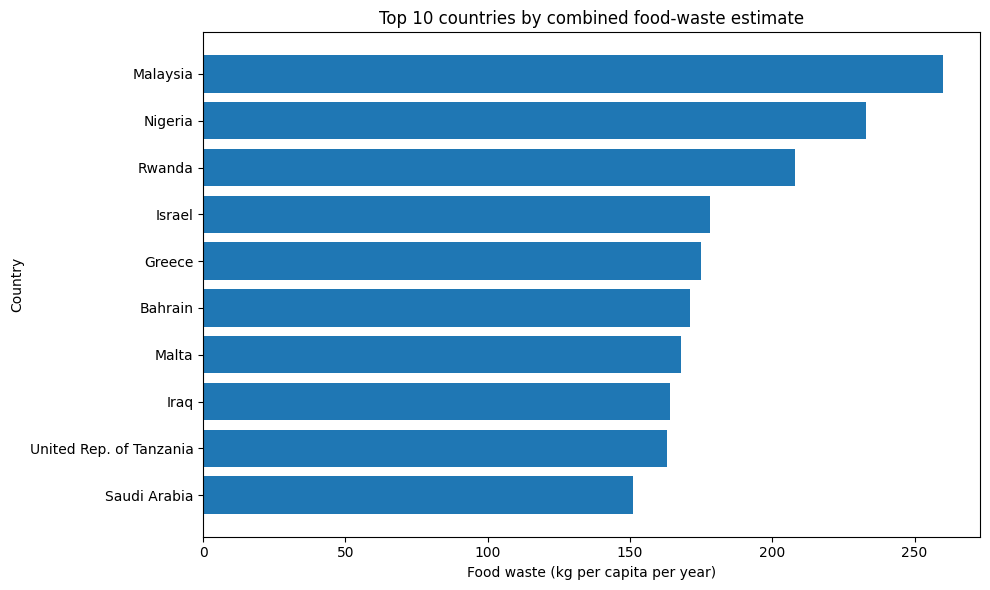

In [4]:
top_countries = df.nlargest(10, "combined figures (kg/capita/year)").sort_values(
    "combined figures (kg/capita/year)"
)
plt.figure(figsize=(10, 6))
plt.barh(top_countries["Country"], top_countries["combined figures (kg/capita/year)"])
plt.xlabel("Food waste (kg per capita per year)")
plt.ylabel("Country")
plt.title("Top 10 countries by combined food-waste estimate")
plt.tight_layout()
plt.show()

## Step 5 — Compare regions

,Average combined food waste (kg/capita/year)
Region,
Sub-Saharan Africa,145.40
Western Asia,145.39
South-eastern Asia,137.45
Northern Africa,133.50
Central Asia,130.20
Melanesia,128.60
Micronesia,123.14
Southern Europe,123.00
Northern America,120.75


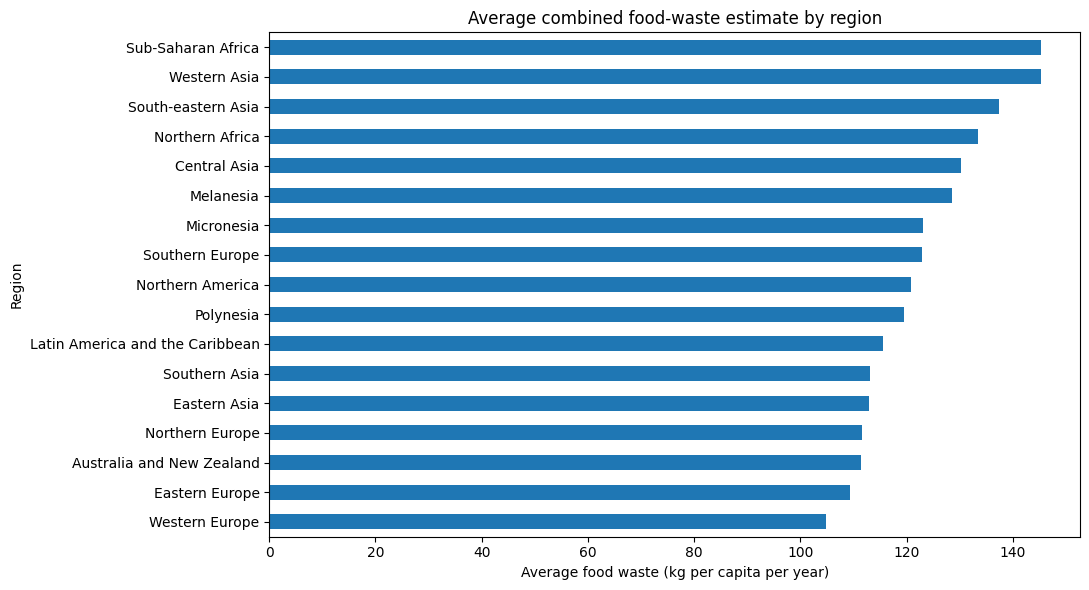

In [5]:
region_summary = (
    df.groupby("Region", dropna=False)["combined figures (kg/capita/year)"]
      .mean().sort_values(ascending=False).dropna()
)
display(region_summary.to_frame("Average combined food waste (kg/capita/year)").round(2))

plt.figure(figsize=(11, 6))
region_summary.sort_values().plot(kind="barh")
plt.xlabel("Average food waste (kg per capita per year)")
plt.ylabel("Region")
plt.title("Average combined food-waste estimate by region")
plt.tight_layout()
plt.show()

## Step 6 — Compare household, retail, and food-service waste

,Average kg per capita per year
Household estimate (kg/capita/year),84.29
Retail estimate (kg/capita/year),15.12
Food service estimate (kg/capita/year),27.38


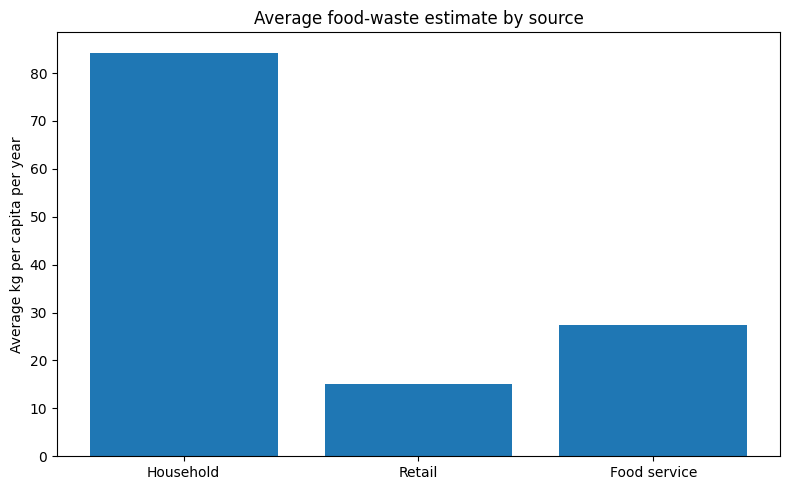

In [6]:
source_cols = [
    "Household estimate (kg/capita/year)",
    "Retail estimate (kg/capita/year)",
    "Food service estimate (kg/capita/year)"
]
source_means = df[source_cols].mean()
display(source_means.to_frame("Average kg per capita per year").round(2))

plt.figure(figsize=(8, 5))
plt.bar(["Household", "Retail", "Food service"], source_means.values)
plt.ylabel("Average kg per capita per year")
plt.title("Average food-waste estimate by source")
plt.tight_layout()
plt.show()

## Step 7 — Prepare data and train the prediction model

**Target:** `Household estimate (tonnes/year)`

To avoid using the target itself or other total-tonnage columns as inputs, the model uses per-capita estimates, region, and confidence level. Country name, source URL, and M49 code are excluded. A Random Forest Regressor learns patterns in the available country-level records.

In [7]:
TARGET = "Household estimate (tonnes/year)"

feature_cols = [
    "combined figures (kg/capita/year)",
    "Household estimate (kg/capita/year)",
    "Retail estimate (kg/capita/year)",
    "Food service estimate (kg/capita/year)",
    "Confidence in estimate",
    "Region"
]

model_df = df[feature_cols + [TARGET]].dropna(subset=[TARGET]).copy()
X = model_df[feature_cols]
y = model_df[TARGET]

numeric_features = [
    "combined figures (kg/capita/year)",
    "Household estimate (kg/capita/year)",
    "Retail estimate (kg/capita/year)",
    "Food service estimate (kg/capita/year)"
]
categorical_features = ["Confidence in estimate", "Region"]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(n_estimators=200, random_state=42))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)
print("Model training complete!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Model training complete!
Training records: 171
Testing records: 43


## Step 8 — Evaluate model performance

In [8]:
mae = mean_absolute_error(y_test, predictions)
rmse = mean_squared_error(y_test, predictions) ** 0.5
r2 = r2_score(y_test, predictions)

print("Mean Absolute Error (MAE):", round(mae, 2), "tonnes/year")
print("Root Mean Squared Error (RMSE):", round(rmse, 2), "tonnes/year")
print("R² Score:", round(r2, 3))

print("\\nHow to read these metrics:")
print("- MAE: average absolute prediction error; lower is better.")
print("- RMSE: penalizes larger errors more; lower is better.")
print("- R²: compares predictions with a simple mean baseline; closer to 1 is generally better.")

Mean Absolute Error (MAE): 3905561.6 tonnes/year
Root Mean Squared Error (RMSE): 8167413.69 tonnes/year
R² Score: -4.58
\nHow to read these metrics:
- MAE: average absolute prediction error; lower is better.
- RMSE: penalizes larger errors more; lower is better.
- R²: compares predictions with a simple mean baseline; closer to 1 is generally better.


## Step 9 — Compare actual and predicted household waste

,Actual household waste (tonnes/year),Predicted household waste (tonnes/year)
0,2563110,1050837.19
1,2824,161677.99
2,3710,112216.98
3,830017,2093392.03
4,37688,4443959.07
5,2724,275450.92
6,21215,161677.99
7,780504,727862.38
8,2555332,739764.21
9,15947645,2279825.87


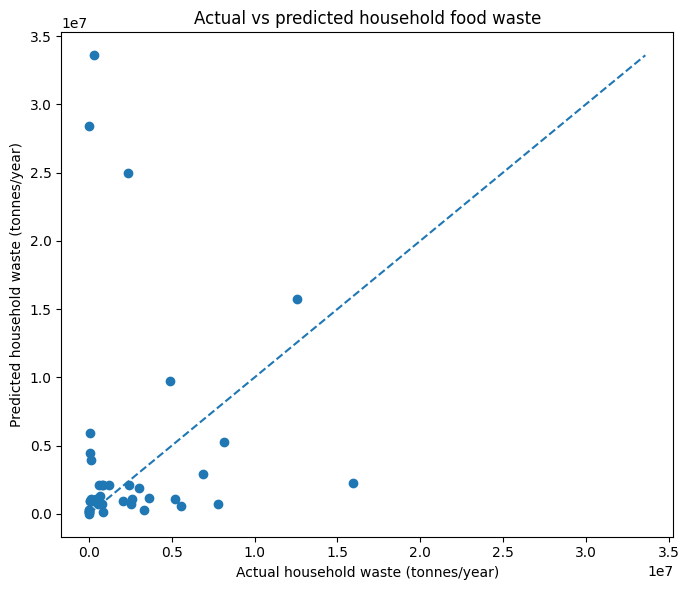

In [9]:
comparison = pd.DataFrame({
    "Actual household waste (tonnes/year)": y_test.reset_index(drop=True),
    "Predicted household waste (tonnes/year)": predictions
})
display(comparison.head(10).round(2))

plt.figure(figsize=(7, 6))
plt.scatter(y_test, predictions)
max_value = max(float(y_test.max()), float(np.max(predictions)))
plt.plot([0, max_value], [0, max_value], linestyle="--")
plt.xlabel("Actual household waste (tonnes/year)")
plt.ylabel("Predicted household waste (tonnes/year)")
plt.title("Actual vs predicted household food waste")
plt.tight_layout()
plt.show()

## Step 10 — Try one example prediction

In [10]:
sample_country = X_test.iloc[[0]]
predicted_tonnes = model.predict(sample_country)[0]
print("Input features:")
display(sample_country)
print("Estimated household food waste:", round(float(predicted_tonnes), 2), "tonnes/year")

Input features:


,combined figures (kg/capita/year),Household estimate (kg/capita/year),Retail estimate (kg/capita/year),Food service estimate (kg/capita/year),Confidence in estimate,Region
9,133,102,9,22,High Confidence,Australia and New Zealand


Estimated household food waste: 1050837.19 tonnes/year


## Step 11 — Save the trained model

In [12]:
joblib.dump(model, "freshtrack_model.pkl")
print("Model saved as freshtrack_model.pkl")

# In Google Colab, uncomment the next two lines to download the model:
# from google.colab import files
# files.download("freshtrack_model.pkl")

Model saved as freshtrack_model.pkl


## Conclusion

- FreshTrack summarizes food-waste estimates across countries and regions.
- It compares household, retail, and food-service waste per capita.
- A Random Forest Regressor estimates household waste in tonnes per year using country-level indicators.
- The model's reliability is limited by the dataset size, uncertainty in source estimates, and the fact that these are country-level records.

